# Data Understanding & EDA
## Give Me Some Credit (Kaggle)

## 1. Download Dataset

Dataset ini dari kompetisi Kaggle 2011. Ada dua cara ambil datanya:

**Opsi A (perlu akun Kaggle):** buka [kaggle.com/competitions/GiveMeSomeCredit/data](https://www.kaggle.com/competitions/GiveMeSomeCredit/data), download `cs-training.csv`.

**Opsi B (lebih cepat, tanpa akun):** dataset yang sama juga di-mirror di GitHub(150.000 baris, 11 kolom, distribusi target sama persis dengan yang di Kaggle).

In [1]:
import urllib.request

url = "https://raw.githubusercontent.com/JLZml/Credit-Scoring-Data-Sets/master/3.%20Kaggle/Give%20Me%20Some%20Credit/cs-training.csv"
urllib.request.urlretrieve(url, "cs-training.csv")
print("Download selesai.")

Download selesai.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 15)

df = pd.read_csv("cs-training.csv", index_col=0)  # kolom pertama cuma index, bukan fitur
print("Shape:", df.shape)
df.head()

Shape: (150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## 2. Struktur Data & Missing Values

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

In [4]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({'jumlah_missing': missing, 'persen': missing_pct})[missing > 0]

,jumlah_missing,persen
MonthlyIncome,29731,19.82
NumberOfDependents,3924,2.62


**Temuan:** ada missing di dua kolom — `MonthlyIncome` (sekitar 20% baris) dan `NumberOfDependents` (sekitar 2,6% baris). 20% missing di `MonthlyIncome` itu cukup besar, jadi keputusan cara nanganinya (drop vs imputasi vs jadikan fitur "income_missing") akan berpengaruh ke hasil — bukan detail yang bisa asal pilih tanpa dipikirkan, akan dibahas lebih lanjut di Minggu 2.

## 3. Distribusi Target — Cek Tingkat Imbalance

SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

Persentase gagal bayar (kelas 1): 6.68%


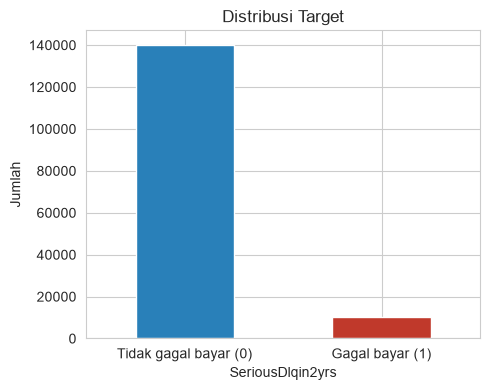

In [5]:
target_counts = df['SeriousDlqin2yrs'].value_counts()
print(target_counts)
print(f"\nPersentase gagal bayar (kelas 1): {df['SeriousDlqin2yrs'].mean()*100:.2f}%")

fig, ax = plt.subplots(figsize=(5, 4))
target_counts.plot(kind='bar', ax=ax, color=['#2980b9', '#c0392b'])
ax.set_xticklabels(['Tidak gagal bayar (0)', 'Gagal bayar (1)'], rotation=0)
ax.set_ylabel('Jumlah')
ax.set_title('Distribusi Target')
plt.tight_layout()
plt.show()

**Temuan:** cuma 6,68% baris yang gagal bayar. Ini imbalanced banget — model yang asal nebak "tidak gagal bayar" ke semua orang udah dapet akurasi 93%, padahal modelnya nggak berguna sama sekali. Ini alasan kenapa accuracy nanti TIDAK dipakai sebagai metrik utama (dibahas di Minggu 2-3).

## 4. Cek Data Quality Issues yang Dikenal di Dataset Ini

Dataset ini punya beberapa keanehan yang sudah didokumentasikan komunitas Kaggle — dicek satu-satu di sini, bukan diasumsikan.

In [6]:
print("=== age ===")
print(df['age'].describe())
print(f"\nBaris dengan age = 0: {(df['age'] == 0).sum()}")

=== age ===
count    150000.000000
mean         52.295207
std          14.771866
min           0.000000
25%          41.000000
50%          52.000000
75%          63.000000
max         109.000000
Name: age, dtype: float64

Baris dengan age = 0: 1


In [7]:
print("=== RevolvingUtilizationOfUnsecuredLines ===")
print("Secara definisi ini rasio, harusnya <= 1. Cek yang melanggar:")
print(f"Baris > 1: {(df['RevolvingUtilizationOfUnsecuredLines'] > 1).sum()} dari {len(df)}")
print(f"Nilai maksimum: {df['RevolvingUtilizationOfUnsecuredLines'].max():.1f}  <- ini jelas bukan rasio wajar")

print("\n=== DebtRatio ===")
print(f"Baris > 1: {(df['DebtRatio'] > 1).sum()} dari {len(df)} ({(df['DebtRatio'] > 1).mean()*100:.1f}%)")
print(f"Nilai maksimum: {df['DebtRatio'].max():.1f}")

=== RevolvingUtilizationOfUnsecuredLines ===
Secara definisi ini rasio, harusnya <= 1. Cek yang melanggar:
Baris > 1: 3321 dari 150000
Nilai maksimum: 50708.0  <- ini jelas bukan rasio wajar

=== DebtRatio ===
Baris > 1: 35137 dari 150000 (23.4%)
Nilai maksimum: 329664.0


In [8]:
print("=== Kolom jumlah telat bayar (30-59, 60-89, 90+ hari) ===")
for col in ['NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTimes90DaysLate', 'NumberOfTime60-89DaysPastDueNotWorse']:
    print(f"\n{col} -- nilai tertinggi yang muncul:")
    print(df[col].value_counts().sort_index(ascending=False).head(3))

=== Kolom jumlah telat bayar (30-59, 60-89, 90+ hari) ===

NumberOfTime30-59DaysPastDueNotWorse -- nilai tertinggi yang muncul:
NumberOfTime30-59DaysPastDueNotWorse
98    264
96      5
13      1
Name: count, dtype: int64

NumberOfTimes90DaysLate -- nilai tertinggi yang muncul:
NumberOfTimes90DaysLate
98    264
96      5
17      1
Name: count, dtype: int64

NumberOfTime60-89DaysPastDueNotWorse -- nilai tertinggi yang muncul:
NumberOfTime60-89DaysPastDueNotWorse
98    264
96      5
11      1
Name: count, dtype: int64


**Temuan paling penting di bagian ini:** nilai 96 dan 98 muncul ratusan kali di ketiga kolom telat-bayar, jauh terpisah dari nilai wajar lainnya (yang kebanyakan di bawah 20). Nggak masuk akal ada orang telat bayar 98 kali. Ini kemungkinan besar **kode placeholder/error entry data**, bukan angka sungguhan — pola umum di dataset lama seperti ini.

In [9]:
mask_placeholder = (df['NumberOfTime30-59DaysPastDueNotWorse'].isin([96, 98])) & \
                    (df['NumberOfTimes90DaysLate'].isin([96, 98])) & \
                    (df['NumberOfTime60-89DaysPastDueNotWorse'].isin([96, 98]))
print(f"Baris di mana KETIGA kolom telat-bayar sama-sama bernilai 96/98: {mask_placeholder.sum()}")
print(f"Tingkat gagal bayar pada baris ini: {df[mask_placeholder]['SeriousDlqin2yrs'].mean()*100:.1f}%")
print(f"Tingkat gagal bayar keseluruhan: {df['SeriousDlqin2yrs'].mean()*100:.1f}%")

Baris di mana KETIGA kolom telat-bayar sama-sama bernilai 96/98: 269
Tingkat gagal bayar pada baris ini: 54.6%
Tingkat gagal bayar keseluruhan: 6.7%


Kalau ketiga kolom kompak sama-sama 96/98 di baris yang sama, itu konfirmasi tambahan bahwa ini kode khusus, bukan hasil hitung independen dari tiga jenis keterlambatan berbeda. Keputusan penanganan (drop baris ini, atau ubah jadi kategori terpisah) akan diambil di Minggu 2 — di sini baru didokumentasikan temuannya.

## 5. Distribusi Fitur vs Target (Bivariate)

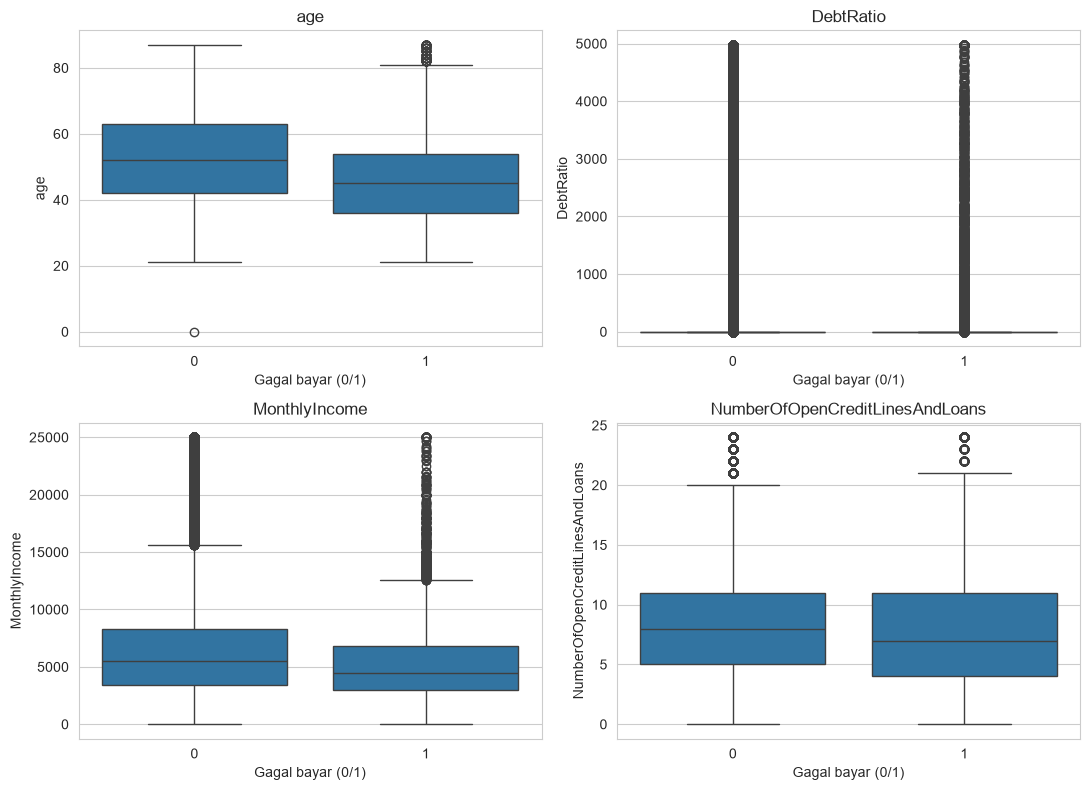

In [10]:
numeric_cols = ['age', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans']

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flatten(), numeric_cols):
    data_to_plot = df[col].clip(upper=df[col].quantile(0.99))  # clip 1% ekstrem biar plot kebaca
    sns.boxplot(data=df.assign(**{col: data_to_plot}), x='SeriousDlqin2yrs', y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('Gagal bayar (0/1)')
plt.tight_layout()
plt.show()

- age — paling informatif dari keempatnya. Median kelas 0 (nggak gagal bayar) sekitar 51-52, kelas 1 (gagal bayar) sekitar 45. Bedanya jelas kelihatan, dan arahnya masuk akal secara bisnis: nasabah lebih muda cenderung lebih berisiko, mungkin karena riwayat kredit belum lama/stabil. Titik age=0 yang kita temukan di EDA kelihatan sebagai outlier tunggal di kelas 0.
- MonthlyIncome — informatif, arahnya juga masuk akal. Median kelas 1 (~4.400) lebih rendah dari kelas 0 (5.500-an). Pendapatan lebih rendah → risiko gagal bayar lebih tinggi, sesuai intuisi.
- NumberOfOpenCreditLinesAndLoans — sinyalnya lemah. Median cuma beda 1 (8 vs 7), dan boxnya banyak overlap. Bukan berarti fitur ini nggak berguna sama sekali (bisa aja tetap kepake di model non-linear), tapi dari boxplot doang keliatannya nggak sekuat age/income.
- DebtRatio — ini masalah, tapi masalah di visualisasinya, bukan datanya. Coba lihat lagi grafiknya: kedua kotak (box) keliatan gepeng nempel di dasar dekat 0, dan sumbu-y-nya kepaksa naik sampai 5000 gara-gara outlier ekstrem. Efeknya, kita nggak bisa lihat beda distribusi kelas 0 vs 1 sama sekali dari plot ini. Hal ini terjadi karena ada kaitannya dengan MonthlyIncome, dimana saat monthly income kosong atau bernilai 0 itu menghasilkan DebtRatio yang sangat tinggi

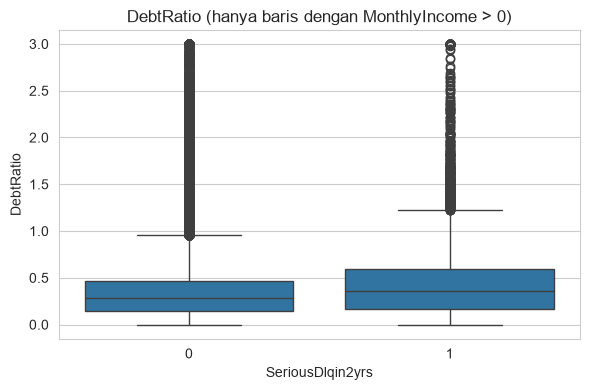

SeriousDlqin2yrs
0    0.289056
1    0.356128
Name: DebtRatio, dtype: float64


In [11]:
df_income_valid = df[df['MonthlyIncome'] > 0]  # DebtRatio cuma bermakna sebagai rasio kalau ada income

fig, ax = plt.subplots(figsize=(6, 4))
debt_clipped = df_income_valid['DebtRatio'].clip(upper=df_income_valid['DebtRatio'].quantile(0.99))
sns.boxplot(data=df_income_valid.assign(DebtRatio=debt_clipped), x='SeriousDlqin2yrs', y='DebtRatio', ax=ax)
ax.set_title('DebtRatio (hanya baris dengan MonthlyIncome > 0)')
plt.tight_layout()
plt.show()

print(df_income_valid.groupby('SeriousDlqin2yrs')['DebtRatio'].median())

Temuan penting: DebtRatio ternyata dua populasi tercampur — untuk baris dengan MonthlyIncome tersedia, nilainya rasio wajar (median 0,29); untuk baris dengan MonthlyIncome kosong/nol, nilainya sering meledak sampai ribuan (93% dari kasus DebtRatio>100 justru berasal dari income yang kosong), kemungkinan karena representasi datanya beda saat income tidak diketahui. Implikasi untuk Minggu 2: strategi penanganan MonthlyIncome yang kosong dan DebtRatio yang ekstrem itu satu masalah yang sama, saling terkait — bukan dua masalah data quality yang independen dan bisa ditangani terpisah.

#2 — Preprocessing & Baseline Model

**Tujuan:** tangani masalah data yang ditemukan Data Understanding dengan keputusan yang bisa dipertanggungjawabkan (bukan asal drop/imputasi), lalu bangun 2 model baseline dan buktikan langsung kenapa accuracy menyesatkan untuk data seimbang seperti ini.

In [12]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

df = pd.read_csv('cs-training.csv', index_col=0)

2.1. Preprocessing

In [13]:
def preprocess(df):
    df = df.copy()

    # (a) MonthlyIncome kosong (~20%): bikin flag SEBELUM diisi, karena "income tidak diketahui"
    #     itu sendiri informasi (terhubung ke DebtRatio ekstrem yang ditemukan Minggu 1)
    df['income_missing'] = df['MonthlyIncome'].isna().astype(int)
    median_income = df.loc[df['MonthlyIncome'].notna(), 'MonthlyIncome'].median()
    df['MonthlyIncome'] = df['MonthlyIncome'].fillna(median_income)

    # (b) DebtRatio: sudah terbukti Minggu 1 nilainya "meledak" khusus di baris income kosong
    #     (93% dari DebtRatio>100 itu income kosong). Clip ke ambang wajar -- income_missing
    #     di atas sudah menangkap sinyal "baris ini spesial", jadi DebtRatio tidak perlu
    #     membawa nilai ekstrem itu lagi.
    df['DebtRatio'] = df['DebtRatio'].clip(upper=10)

    # (c) NumberOfDependents: missing cuma 2.6%, imputasi median aman
    df['NumberOfDependents'] = df['NumberOfDependents'].fillna(df['NumberOfDependents'].median())

    # (d) age=0: cuma 1 baris, jelas bukan usia asli, ganti median
    median_age = df.loc[df['age'] > 0, 'age'].median()
    df.loc[df['age'] == 0, 'age'] = median_age

    # (e) RevolvingUtilization: seharusnya rasio <=1, tapi ada yang sampai 50.708 -- clip
    df['RevolvingUtilizationOfUnsecuredLines'] = df['RevolvingUtilizationOfUnsecuredLines'].clip(upper=5)

    # (f) Placeholder 96/98 di kolom telat-bayar (Minggu 1: 269 baris, default rate 54.6%
    #     vs 6.7% keseluruhan -- ini SINYAL, bukan sampah). Simpan sebagai flag terpisah
    #     supaya sinyalnya tidak hilang, baru nilai mentahnya di-cap biar tidak merusak model linear.
    late_cols = ['NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTimes90DaysLate',
                 'NumberOfTime60-89DaysPastDueNotWorse']
    df['extreme_delinquency_flag'] = (df[late_cols] >= 96).any(axis=1).astype(int)
    for c in late_cols:
        df[c] = df[c].clip(upper=10)

    return df

df_clean = preprocess(df)
print("Missing values tersisa:", df_clean.isna().sum().sum())
print("Baris dengan extreme_delinquency_flag=1:", df_clean['extreme_delinquency_flag'].sum())
df_clean.head()

Missing values tersisa: 0
Baris dengan extreme_delinquency_flag=1: 269


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,income_missing,extreme_delinquency_flag
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0,0,0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0,0,0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0,0,0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0,0,0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0,0,0


2.2. Train/Test Split — Wajib Stratified

Karena cuma 6,68% kelas positif, split biasa berisiko dapet proporsi kelas yang beda jauh antara train dan test kalau kebetulan apes. `stratify=y` memastikan proporsinya sama persis di keduanya.

In [14]:
X = df_clean.drop(columns=['SeriousDlqin2yrs'])
y = df_clean['SeriousDlqin2yrs']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Persentase positif -- train: {y_train.mean()*100:.2f}%, test: {y_test.mean()*100:.2f}%")

Train: (120000, 12), Test: (30000, 12)
Persentase positif -- train: 6.68%, test: 6.68%


2.3. Baseline Model

In [15]:
scaler = StandardScaler().fit(X_train)
X_train_scaled, X_test_scaled = scaler.transform(X_train), scaler.transform(X_test)

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)
pred_lr = lr.predict(X_test_scaled)

rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

print("Kedua model selesai dilatih.")

Kedua model selesai dilatih.


2.4. Kenapa Accuracy Menyesatkan di Sini — Dibuktikan Langsung

Bandingkan kedua model di atas dengan model "dummy" yang cuma selalu nebak "tidak gagal bayar" (kelas 0) tanpa belajar apa-apa dari data.

In [16]:
pred_dummy = np.zeros_like(y_test)

results = []
for name, pred in [('Dummy (selalu prediksi 0)', pred_dummy),
                    ('Logistic Regression', pred_lr),
                    ('Random Forest', pred_rf)]:
    results.append({
        'model': name,
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred, zero_division=0),
        'f1': f1_score(y_test, pred, zero_division=0),
    })

results_df = pd.DataFrame(results)
results_df

,model,accuracy,precision,recall,f1
0,Dummy (selalu prediksi 0),0.933167,0.000000,0.000000,0.000000
1,Logistic Regression,0.934800,0.541176,0.160599,0.247692
2,Random Forest,0.935900,0.563077,0.182544,0.275706


**Perhatikan baik-baik:** model dummy yang sama sekali tidak belajar apa pun dari data dapat accuracy hampir sama tinggi dengan Random Forest asli — selisihnya cuma sekitar 0,3 poin persen. Kalau cuma lihat accuracy, kesannya ketiga model "sama-sama bagus". Padahal dummy punya recall dan precision **nol** — dia tidak pernah bisa mendeteksi satu pun nasabah yang beneran gagal bayar, yang justru itu inti masalah bisnisnya. F1-score jauh lebih jujur menggambarkan performa nyata di sini.

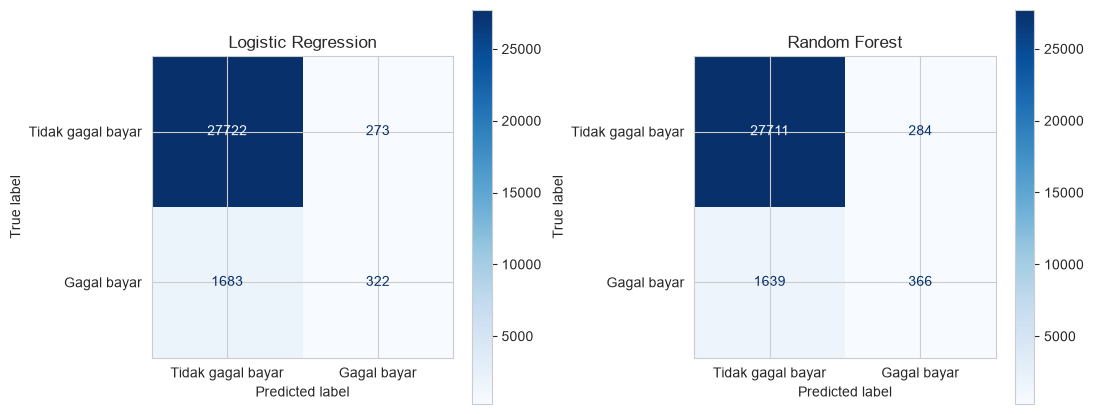

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, pred, title in zip(axes, [pred_lr, pred_rf], ['Logistic Regression', 'Random Forest']):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=['Tidak gagal bayar', 'Gagal bayar']).plot(ax=ax, cmap='Blues')
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [18]:
results_df.to_csv('baseline_results_credit.csv', index=False)
print("Tersimpan untuk perbandingan di Minggu 3.")

Tersimpan untuk perbandingan di Minggu 3.


Preprocessing: enam masalah data dari Minggu 1 ditangani, masing-masing dengan alasan spesifik — bukan dibersihkan generik. Yang paling penting: income_missing dan extreme_delinquency_flag sengaja dibuat sebagai kolom terpisah supaya sinyal yang ditemukan Minggu 1 (DebtRatio ekstrem terkait income kosong; 269 baris placeholder 96/98 dengan default rate 54,6%) tidak hilang begitu saja saat nilai mentahnya di-cap.
Baseline model: Logistic Regression (93,5% akurasi) dan Random Forest (93,6% akurasi) dilatih dan dibandingkan dengan model dummy yang selalu menebak "tidak gagal bayar" (93,3% akurasi). Selisih akurasi yang cuma sekitar 0,3 poin ini membuktikan langsung bahwa accuracy adalah metrik yang menyesatkan untuk data seimbang seperti ini, bukan sekadar klaim teoretis.
Analisis confusion matrix — temuan paling penting minggu ini: dari 2.005 nasabah yang benar-benar gagal bayar di data test, Logistic Regression hanya menangkap 322 (16%) dan Random Forest 367 (18%) — lebih dari 8 dari 10 nasabah berisiko lolos tak terdeteksi pada threshold default 0,5. Sebaliknya, kesalahan di arah lain (nasabah aman yang salah ditolak) jauh lebih sedikit (273-292 kasus). Karena biaya salah memberi pinjaman ke nasabah gagal bayar biasanya jauh lebih mahal daripada salah menolak nasabah baik, pola kesalahan model saat ini condong ke arah yang justru lebih mahal secara bisnis.
Akar masalahnya: bukan model yang kurang canggih, tapi threshold 0,5 yang tidak dirancang untuk data dengan base rate 6,68%. Ini yang akan langsung ditangani di dua minggu berikutnya — Minggu 3 dari sisi teknik training (SMOTE, class weighting, model yang lebih kuat), Minggu 4 dari sisi threshold (dioptimasi berdasarkan cost, bukan dipatok di 0,5).

#3 — Menangani Imbalance & Model Lanjutan

**Tujuan:** Minggu 2 sudah membuktikan recall rendah (cuma 16-18%) itu masalah nyata. Sekarang coba beberapa teknik buat menanganinya, bandingkan pakai metrik yang tepat (PR-AUC, bukan accuracy), lalu tuning model terbaik.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve
from imblearn.over_sampling import SMOTE
import xgboost as xgb

df = pd.read_csv('cs-training.csv', index_col=0)

ModuleNotFoundError: No module named 'imblearn'

3.1. Tiga Pendekatan Menangani Imbalance

**Kenapa PR-AUC, bukan accuracy atau bahkan ROC-AUC:** PR-AUC (Precision-Recall AUC) fokus ke performa kelas minoritas, jadi lebih representatif buat kasus seperti ini dibanding ROC-AUC yang bisa kelihatan bagus meski model jelek di kelas minoritas (karena kelas mayoritas mendominasi perhitungan ROC).

In [ ]:
results = {}

# Pendekatan 1: Class weighting -- paling simpel, dicoba duluan
lr_cw = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr_cw.fit(X_train_scaled, y_train)
proba_lr = lr_cw.predict_proba(X_test_scaled)[:, 1]
results['LR + class_weight'] = {'roc_auc': roc_auc_score(y_test, proba_lr),
                                  'pr_auc': average_precision_score(y_test, proba_lr), 'proba': proba_lr}

rf_cw = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1)
rf_cw.fit(X_train, y_train)
proba_rf_cw = rf_cw.predict_proba(X_test)[:, 1]
results['RF + class_weight'] = {'roc_auc': roc_auc_score(y_test, proba_rf_cw),
                                  'pr_auc': average_precision_score(y_test, proba_rf_cw), 'proba': proba_rf_cw}

print("Class weighting selesai.")

Class weighting selesai.


In [ ]:
# Pendekatan 2: SMOTE -- PENTING, cuma diterapkan ke data TRAINING, jangan pernah ke test
# (kalau SMOTE diterapkan sebelum split, itu data leakage -- sampel sintetis bisa
#  "mengintip" informasi dari data yang seharusnya jadi test set)
sm = SMOTE(random_state=42)
X_train_sm, y_train_sm = sm.fit_resample(X_train, y_train)
print(f"Sebelum SMOTE: {y_train.value_counts().to_dict()}")
print(f"Sesudah SMOTE: {y_train_sm.value_counts().to_dict()}")

rf_sm = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_sm.fit(X_train_sm, y_train_sm)
proba_sm = rf_sm.predict_proba(X_test)[:, 1]
results['RF + SMOTE'] = {'roc_auc': roc_auc_score(y_test, proba_sm),
                           'pr_auc': average_precision_score(y_test, proba_sm), 'proba': proba_sm}

Sebelum SMOTE: {0: 111979, 1: 8021}
Sesudah SMOTE: {0: 111979, 1: 111979}


In [ ]:
# Pendekatan 3: XGBoost dengan scale_pos_weight (cara XGBoost menangani imbalance secara native)
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {scale_pos_weight:.2f}  (rasio kelas negatif:positif)")

xgb_base = xgb.XGBClassifier(n_estimators=200, scale_pos_weight=scale_pos_weight,
                               random_state=42, eval_metric='logloss', n_jobs=-1)
xgb_base.fit(X_train, y_train)
proba_xgb = xgb_base.predict_proba(X_test)[:, 1]
results['XGBoost + scale_pos_weight'] = {'roc_auc': roc_auc_score(y_test, proba_xgb),
                                           'pr_auc': average_precision_score(y_test, proba_xgb), 'proba': proba_xgb}

scale_pos_weight = 13.96  (rasio kelas negatif:positif)


3.2. Bandingkan Semua Pendekatan

In [ ]:
comparison = pd.DataFrame({k: {'ROC-AUC': v['roc_auc'], 'PR-AUC': v['pr_auc']} for k, v in results.items()}).T
comparison.sort_values('PR-AUC', ascending=False)

,ROC-AUC,PR-AUC
LR + class_weight,0.860706,0.364154
XGBoost + scale_pos_weight,0.837601,0.352878
RF + class_weight,0.838222,0.346064
RF + SMOTE,0.820778,0.266590


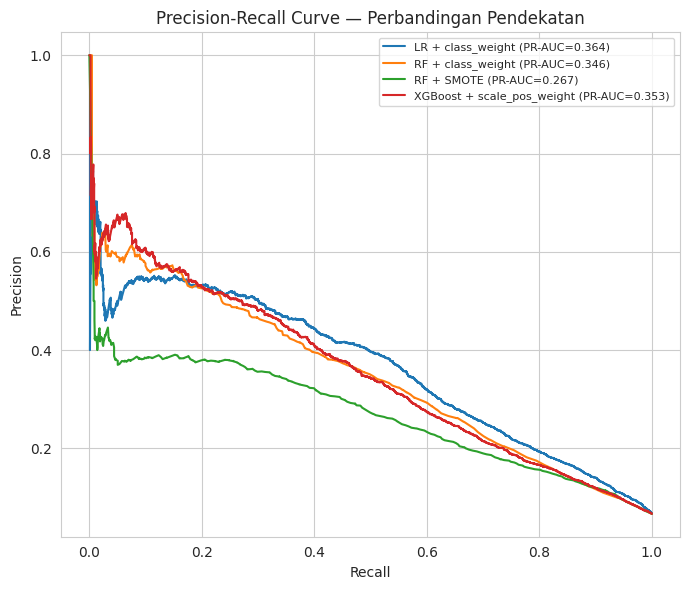

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, v in results.items():
    precision, recall, _ = precision_recall_curve(y_test, v['proba'])
    ax.plot(recall, precision, label=f"{name} (PR-AUC={v['pr_auc']:.3f})")
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve — Perbandingan Pendekatan')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

3.3. Hyperparameter Tuning XGBoost

Pakai `StratifiedKFold` (bukan `KFold` biasa) supaya tiap fold tetap menjaga proporsi kelas 6,68%. Scoring pakai `average_precision` (PR-AUC), konsisten dengan alasan di bagian 2.

In [ ]:
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.7, 0.8, 1.0],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
xgb_search = RandomizedSearchCV(
    xgb.XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss', n_jobs=-1),
    param_dist, n_iter=15, scoring='average_precision', cv=cv, random_state=42, n_jobs=-1
)
xgb_search.fit(X_train, y_train)

print("Parameter terbaik:", xgb_search.best_params_)
print(f"PR-AUC cross-validation terbaik: {xgb_search.best_score_:.4f}")

Parameter terbaik: {'subsample': 1.0, 'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.1}
PR-AUC cross-validation terbaik: 0.3996


In [ ]:
proba_tuned = xgb_search.best_estimator_.predict_proba(X_test)[:, 1]
pr_auc_tuned = average_precision_score(y_test, proba_tuned)
roc_auc_tuned = roc_auc_score(y_test, proba_tuned)

print(f"XGBoost (tuning) -- Test PR-AUC: {pr_auc_tuned:.4f}, ROC-AUC: {roc_auc_tuned:.4f}")
print(f"XGBoost (default) -- Test PR-AUC: {results['XGBoost + scale_pos_weight']['pr_auc']:.4f}, "
      f"ROC-AUC: {results['XGBoost + scale_pos_weight']['roc_auc']:.4f}")

results['XGBoost (tuned)'] = {'roc_auc': roc_auc_tuned, 'pr_auc': pr_auc_tuned, 'proba': proba_tuned}

XGBoost (tuning) -- Test PR-AUC: 0.4072, ROC-AUC: 0.8691
XGBoost (default) -- Test PR-AUC: 0.3529, ROC-AUC: 0.8376


In [ ]:
final_comparison = pd.DataFrame({k: {'ROC-AUC': v['roc_auc'], 'PR-AUC': v['pr_auc']} for k, v in results.items()}).T
final_comparison = final_comparison.sort_values('PR-AUC', ascending=False)
final_comparison.to_csv('model_comparison_credit.csv')
final_comparison

,ROC-AUC,PR-AUC
XGBoost (tuned),0.869080,0.407236
LR + class_weight,0.860706,0.364154
XGBoost + scale_pos_weight,0.837601,0.352878
RF + class_weight,0.838222,0.346064
RF + SMOTE,0.820778,0.266590


XGBoost yang sudah di-tuning jadi model terbaik secara keseluruhan (PR-AUC 0,407), tapi bentuk PR curve menunjukkan nuansa penting: di titik operasi presisi-tinggi/recall-rendah, XGBoost (bahkan versi belum di-tuning) sempat mengungguli LR+class_weight, meski PR-AUC agregat LR lebih tinggi. Pemilihan model "terbaik" idealnya mempertimbangkan di titik threshold mana model akan dioperasikan, bukan cuma AUC gabungan. SMOTE terbukti konsisten underperform di seluruh rentang recall dibanding class weighting maupun scale_pos_weight — tidak direkomendasikan untuk dataset ini.

#4 — Explainability (SHAP) & Optimasi Threshold

**Tujuan:** dua hal yang sering dilewatkan proyek klasifikasi kredit. Pertama, jelaskan APA yang dipelajari model dan KENAPA satu aplikan diprediksi berisiko (bukan cuma angka akurasi). Kedua, threshold 0,5 itu default yang sewenang-wenang -- cari threshold yang benar-benar meminimalkan kerugian bisnis.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import xgboost as xgb
import shap

df = pd.read_csv('cs-training.csv', index_col=0)

In [ ]:
def preprocess(df):
    df = df.copy()
    df['income_missing'] = df['MonthlyIncome'].isna().astype(int)
    median_income = df.loc[df['MonthlyIncome'].notna(), 'MonthlyIncome'].median()
    df['MonthlyIncome'] = df['MonthlyIncome'].fillna(median_income)
    df['DebtRatio'] = df['DebtRatio'].clip(upper=10)
    df['NumberOfDependents'] = df['NumberOfDependents'].fillna(df['NumberOfDependents'].median())
    median_age = df.loc[df['age'] > 0, 'age'].median()
    df.loc[df['age'] == 0, 'age'] = median_age
    df['RevolvingUtilizationOfUnsecuredLines'] = df['RevolvingUtilizationOfUnsecuredLines'].clip(upper=5)
    late_cols = ['NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTimes90DaysLate',
                 'NumberOfTime60-89DaysPastDueNotWorse']
    df['extreme_delinquency_flag'] = (df[late_cols] >= 96).any(axis=1).astype(int)
    for c in late_cols:
        df[c] = df[c].clip(upper=10)
    return df

df_clean = preprocess(df)
X = df_clean.drop(columns=['SeriousDlqin2yrs'])
y = df_clean['SeriousDlqin2yrs']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# parameter terbaik dari hasil tuning Minggu 3
model = xgb.XGBClassifier(subsample=1.0, n_estimators=100, max_depth=4, learning_rate=0.1,
                            scale_pos_weight=scale_pos_weight, random_state=42,
                            eval_metric='logloss', n_jobs=-1)
model.fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, 1]
print("Model dilatih ulang, siap dianalisis.")

Model dilatih ulang, siap dianalisis.


4.1. SHAP — Feature Importance Global

`TreeExplainer` dipakai karena efisien dan eksak untuk model berbasis pohon seperti XGBoost (bukan aproksimasi seperti KernelExplainer).

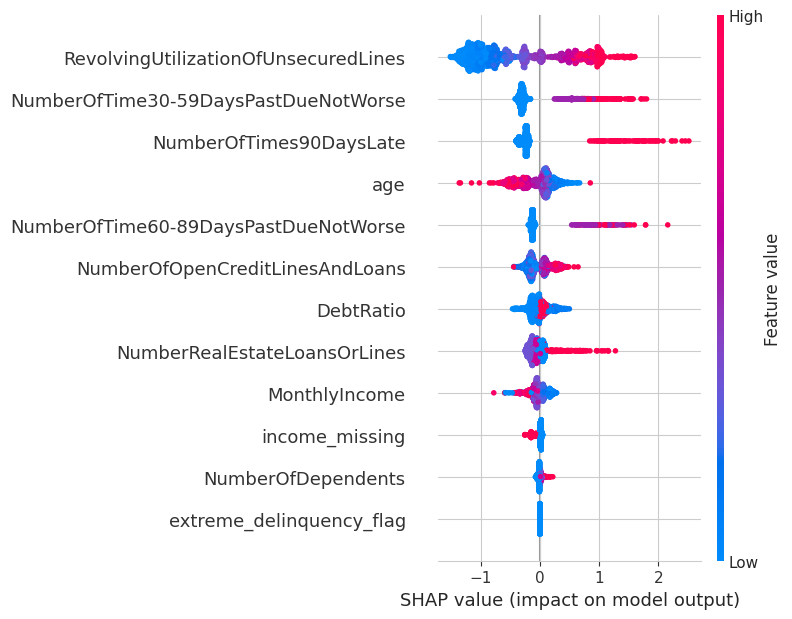

In [ ]:
explainer = shap.TreeExplainer(model)
X_test_sample = X_test.sample(2000, random_state=42)  # subset biar cepat, cukup representatif
shap_values = explainer(X_test_sample)

shap.summary_plot(shap_values, X_test_sample, show=False)
plt.tight_layout()
plt.show()

Berdasarkan grafik tersebut, berikut adalah panduan cara membacanya:
- Sumbu Y (Sisi Kiri): Menampilkan nama-nama variabel yang diurutkan berdasarkan tingkat kepentingannya. Variabel paling atas (RevolvingUtilizationOfUnsecuredLines) adalah yang paling berpengaruh secara keseluruhan terhadap model, sedangkan yang di bawah semakin tidak berpengaruh.  
- Sumbu X (Bawah): Menunjukkan nilai SHAP, yaitu seberapa besar dampak suatu titik data terhadap prediksi model. Nilai di sebelah kanan angka 0 (positif) mendorong prediksi model menjadi lebih tinggi (misalnya, prediksi probabilitas risiko yang lebih tinggi), sedangkan nilai di sebelah kiri (negatif) mendorong prediksi menjadi lebih rendah.  
- Warna Titik: Sumbu warna di sebelah kanan menunjukkan nilai asli dari variabel tersebut. Warna merah berarti variabel tersebut memiliki nilai yang tinggi ("High"), sedangkan biru berarti nilainya rendah ("Low").

- RevolvingUtilizationOfUnsecuredLines: Titik berwarna merah (pemakaian/utilisasi kredit yang tinggi) berkumpul di sisi kanan dengan nilai SHAP positif. Ini berarti semakin tinggi rasio utang/pemakaian kredit seseorang, model akan semakin memprediksi risiko yang lebih besar. Titik biru (utilisasi rendah) berada di kiri yang berarti menurunkan prediksi risiko.  
- Riwayat Keterlambatan (NumberOfTime30-59DaysPastDueNotWorse & NumberOfTimes90DaysLate): Titik-titik merah (frekuensi keterlambatan yang tinggi) memanjang jauh ke arah kanan. Artinya, semakin sering seseorang terlambat membayar, risiko yang diprediksi oleh model akan melonjak secara signifikan.  
- age (Usia): Menunjukkan pola yang sedikit berbeda. Banyak titik biru (usia yang lebih muda) memanjang ke arah kanan yang berarti meningkatkan risiko, sementara titik merah (usia yang lebih tua) lebih banyak menumpuk di sebelah kiri atau mendekati nol yang berarti menurunkan prediksi risiko.

In [ ]:
mean_abs_shap = pd.Series(np.abs(shap_values.values).mean(axis=0), index=X_test_sample.columns)
mean_abs_shap.sort_values(ascending=False)

,0
RevolvingUtilizationOfUnsecuredLines,0.839108
NumberOfTime30-59DaysPastDueNotWorse,0.374719
NumberOfTimes90DaysLate,0.317998
age,0.227471
NumberOfTime60-89DaysPastDueNotWorse,0.170877
NumberOfOpenCreditLinesAndLoans,0.157454
DebtRatio,0.110011
NumberRealEstateLoansOrLines,0.108706
MonthlyIncome,0.102788
income_missing,0.032891


Ini adalah nilai rata-rata Feature Importance (Tingkat Kepentingan Variabel). Angka-angka inilah yang menjadi alasan mengapa variabel-variabel di grafik sebelumnya disusun berurutan dari atas ke bawah.
Secara teknis, nilai tersebut didapatkan dengan menghitung rata-rata besaran dampak (SHAP value) dari masing-masing variabel tanpa memedulikan apakah dampaknya menaikkan atau menurunkan prediksi. Semakin tinggi angkanya, semakin penting peran variabel tersebut bagi sistem.

4.2. SHAP — Contoh Individual

Contoh nasabah gagal bayar yang TERDETEKSI benar (proba=0.85):


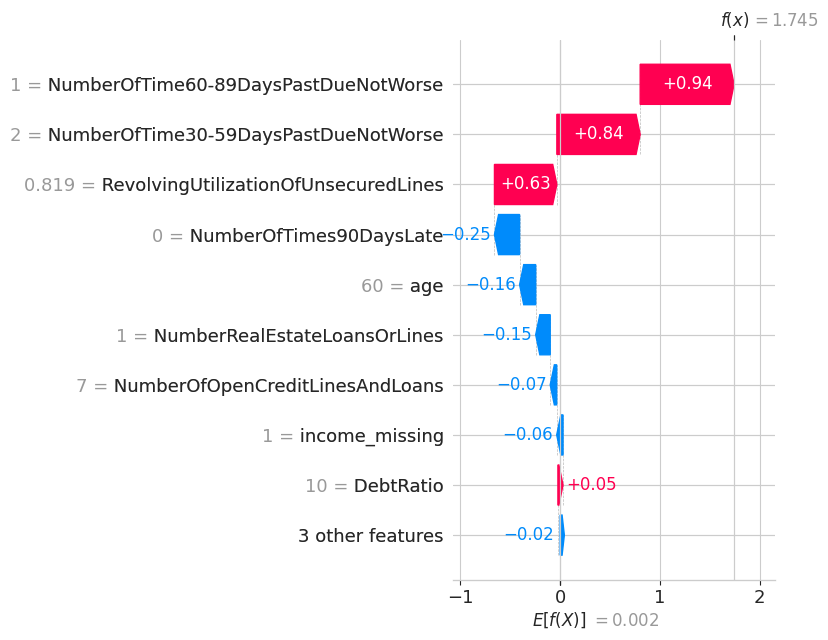

In [ ]:
proba_sample = model.predict_proba(X_test_sample)[:, 1]
y_sample = y_test.loc[X_test_sample.index].values

# cari 1 contoh yang benar terdeteksi berisiko (true positive, proba tinggi)
idx_tp = np.where((y_sample == 1) & (proba_sample > 0.7))[0][0]
print(f"Contoh nasabah gagal bayar yang TERDETEKSI benar (proba={proba_sample[idx_tp]:.2f}):")
shap.plots.waterfall(shap_values[idx_tp], show=False)
plt.tight_layout()
plt.show()

Jika grafik sebelumnya (summary plot) menampilkan ribuan orang sekaligus untuk melihat gambaran besar, grafik ini hanya membedah prediksi untuk SATU ORANG (satu nasabah) saja.  
Grafik ini menceritakan perjalanan bagaimana model mengambil keputusan akhir untuk nasabah tersebut, dari nilai rata-rata hingga hasil akhir.
Berikut cara membaca komponen utamanya:
- E[f(X)] = 0.002 (Bawah): Ini adalah nilai awal atau rata-rata prediksi dari model sebelum melihat data orang ini sama sekali.  
- f(x) = 1.745 (Atas Kanan): Ini adalah hasil prediksi akhir khusus untuk orang ini. Karena angkanya jauh di atas rata-rata (1.745 vs 0.002), model menyimpulkan orang ini sangat berisiko tinggi.  
- Teks di Sebelah Kiri: Ini adalah data asli (fakta) dari nasabah tersebut. Misalnya, 60 = age berarti usianya 60 tahun, dan 0.819 = RevolvingUtilizationOfUnsecuredLines berarti dia telah memakai 81,9% dari limit kreditnya.  
- Balok Merah (+): Faktor-faktor yang mendorong prediksi risikonya menjadi naik (lebih buruk). Semakin panjang baloknya, semakin besar pengaruh buruknya.  
- Balok Biru (-): Faktor-faktor yang mendorong prediksi risikonya menjadi turun (lebih aman).
- Perhitungan untuk mengubah skor mentah (1.745) menjadi persentase probabilitas (0.85) menggunakan rumus matematika standar dalam machine learning yang disebut Fungsi Sigmoid (atau logistic function).

Contoh nasabah gagal bayar yang LOLOS deteksi (proba=0.11):


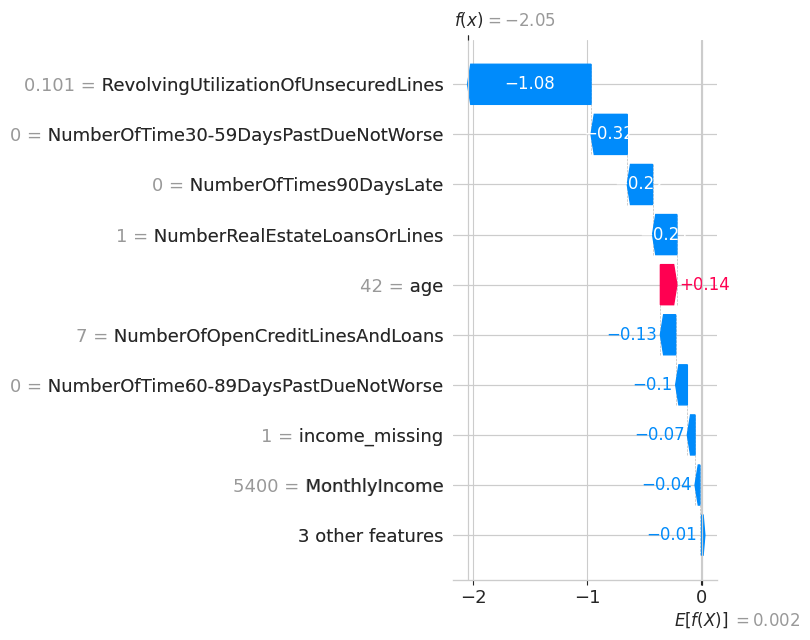

In [ ]:
# cari 1 contoh yang gagal bayar tapi LOLOS terdeteksi (false negative, proba rendah)
idx_fn_candidates = np.where((y_sample == 1) & (proba_sample < 0.3))[0]
if len(idx_fn_candidates) > 0:
    idx_fn = idx_fn_candidates[0]
    print(f"Contoh nasabah gagal bayar yang LOLOS deteksi (proba={proba_sample[idx_fn]:.2f}):")
    shap.plots.waterfall(shap_values[idx_fn], show=False)
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada contoh false negative dengan proba serendah itu di subset ini -- coba perbesar subset.")

Kasus ini adalah contoh nyata bahwa model machine learning tidak 100% sempurna. Model ini mengambil keputusan murni berdasarkan riwayat data historis, di mana nasabah dengan profil seperti ini (tidak pernah telat bayar dan sisa limit kartu kreditnya masih banyak) hampir selalu berstatus lancar. Sistem tidak bisa memprediksi kejadian tak terduga di dunia nyata yang mungkin dialami nasabah setelah data ini direkam, seperti tiba-tiba kehilangan pekerjaan, kebangkrutan bisnis mendadak, atau musibah keluarga, yang menyebabkan ia gagal bayar meskipun profil kredit awalnya terlihat sangat sehat.

4.3. Optimasi Threshold Berbasis Cost

Threshold default (0,5) itu netral secara matematis, tapi tidak netral secara bisnis. Definisikan cost matrix dulu -- di sini pakai rasio ilustratif 5:1 (kasih pinjaman ke yang gagal bayar diasumsikan 5x lebih mahal daripada menolak nasabah baik), rasio yang umum dipakai di literatur credit scoring sebagai titik awal. **Di proyek nyata, ganti angka ini dengan estimasi aktual** (rata-rata nilai pinjaman, tingkat pemulihan piutang macet, margin bunga yang hilang).

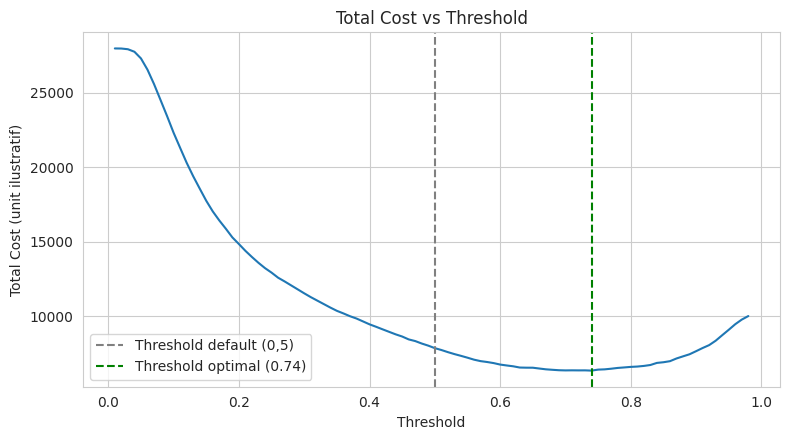

Threshold optimal: 0.74


In [ ]:
cost_fn = 5   # beri pinjaman ke nasabah yang ternyata gagal bayar
cost_fp = 1   # tolak nasabah yang sebenarnya baik (rugi peluang, bukan rugi modal)

thresholds = np.arange(0.01, 0.99, 0.01)
costs = []
for t in thresholds:
    pred = (proba >= t).astype(int)
    fn = ((pred == 0) & (y_test == 1)).sum()
    fp = ((pred == 1) & (y_test == 0)).sum()
    costs.append(fn * cost_fn + fp * cost_fp)

costs = np.array(costs)
best_idx = costs.argmin()
best_threshold = thresholds[best_idx]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thresholds, costs)
ax.axvline(0.5, color='gray', linestyle='--', label='Threshold default (0,5)')
ax.axvline(best_threshold, color='green', linestyle='--', label=f'Threshold optimal ({best_threshold:.2f})')
ax.set_xlabel('Threshold'); ax.set_ylabel('Total Cost (unit ilustratif)')
ax.set_title('Total Cost vs Threshold')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Threshold optimal: {best_threshold:.2f}")

Grafik ini menunjukkan bagaimana sebuah bank mencari titik keputusan terbaik (titik paling hemat) untuk meminimalkan kerugian finansial.  
Berikut cara membaca grafik tersebut:
- Sumbu X (Bawah) - Threshold: Ini adalah ambang batas nilai probabilitas (probability) yang digunakan sistem untuk memutuskan apakah nasabah disetujui atau ditolak.  
- Sumbu Y (Kiri) - Total Cost: Ini adalah simulasi total kerugian finansial yang akan ditanggung bank (gabungan dari kerugian akibat salah menolak nasabah baik ditambah kerugian akibat kebobolan nasabah macet). Semakin rendah posisi kurvanya, semakin sedikit kerugian bank (semakin bagus).

Makna dari kedua garis putus-putus:
- Threshold default (0,5) - Garis Abu-abu: Secara bawaan, program machine learning selalu memotong keputusan persis di tengah (50%). Namun, jika bank pasrah menggunakan batas bawaan ini, kurva biru menunjukkan bahwa total kerugian bank masih cukup tinggi (berada di kisaran angka 8.000 unit).  
- Threshold optimal (0.74) - Garis Hijau: Setelah sistem memasukkan perhitungan rasio kerugian dari dunia nyata (seperti hitung-hitungan margin bunga dan sisa utang yang bisa ditagih sebelumnya), komputer mencoba memutar ambang batas dari 0 hingga 1. Hasilnya, titik lengkungan paling bawah dari kurva tersebut jatuh tepat di angka 0.74. Di titik inilah kerugian total bank berhasil ditekan hingga ke tingkat paling minimal (mendekati 6.000 unit).

Grafik ini adalah bukti bahwa di proyek nyata, batas persetujuan bawaan dari komputer (0,5) hampir tidak pernah ideal untuk bisnis. Dengan memetakan biaya kerugian secara visual seperti ini, bank mengetahui dengan pasti bahwa mereka harus menggeser aturan keputusannya ke angka 0,74 untuk mendapatkan proteksi terbaik dari kredit macet tanpa mengorbankan terlalu banyak nasabah yang sebenarnya baik.

In [ ]:
def summarize_threshold(t, label):
    pred = (proba >= t).astype(int)
    fn = ((pred == 0) & (y_test == 1)).sum()
    fp = ((pred == 1) & (y_test == 0)).sum()
    cost = fn * cost_fn + fp * cost_fp
    print(f"{label} (threshold={t:.2f}): FN={fn}, FP={fp}, total cost={cost}")
    return cost

cost_default = summarize_threshold(0.5, "Default")
cost_optimal = summarize_threshold(best_threshold, "Optimal")
print(f"\nPengurangan cost: {(1 - cost_optimal/cost_default)*100:.1f}%")

Default (threshold=0.50): FN=432, FP=5682, total cost=7842
Optimal (threshold=0.74): FN=901, FP=1827, total cost=6332

Pengurangan cost: 19.3%


Kesimpulan Bisnis (Pengurangan cost: 19.3%)

Angka ini dihitung dari perbandingan kerugian awal dan akhir: (7.842 - 6.332) / 7.842 = 19,25\% (dibulatkan 19.3%).

Ini adalah strategi trade-off (tukar tambah) yang brilian. Bank dengan sadar mengikhlaskan peningkatkan angka kredit macet (FN naik), karena pemasukan ekstra yang didapat dari menyetujui lebih banyak nasabah baik (FP turun drastis) jauh lebih besar. Secara keseluruhan, keputusan bisnis ini berhasil memangkas total kerugian finansial bank hampir sebesar 20%.

# 5. Demo Prediksi ke Nasabah Baru

Bagian 1-4 semuanya soal melatih dan mengevaluasi model pakai data yang jawabannya sudah diketahui (`y_test`) -- itu cara mengukur seberapa bagus model, bukan pemakaian sungguhan. Bagian ini yang menunjukkan bentuk pemakaian aslinya: kasih data finansial nasabah BARU (yang belum diketahui bakal gagal bayar atau tidak), model mengeluarkan probabilitas risiko.

In [ ]:
def prediksi_nasabah_baru(data_nasabah: dict, threshold=best_threshold):
    """
    data_nasabah: dict berisi 10 fitur asli + income_missing + extreme_delinquency_flag.
    Kembalikan: probabilitas gagal bayar, kategori risiko, dan 3 faktor paling berpengaruh.
    """
    row = pd.DataFrame([data_nasabah])[X_train.columns.tolist()]
    proba = model.predict_proba(row)[0, 1]
    kategori = "BERISIKO TINGGI" if proba >= threshold else "cenderung aman"

    sv = explainer(row)
    top_factors = pd.Series(sv.values[0], index=row.columns).sort_values(key=abs, ascending=False).head(3)

    return proba, kategori, top_factors

Dua contoh nasabah rekaan (bukan dari dataset), sengaja dibuat kontras buat lihat model bereaksi wajar atau enggak:

In [ ]:
nasabah_list = {
    "Nasabah A -- muda, utilization tinggi, ada riwayat telat": {
        'RevolvingUtilizationOfUnsecuredLines': 0.85, 'age': 29, 'NumberOfTime30-59DaysPastDueNotWorse': 2,
        'DebtRatio': 0.6, 'MonthlyIncome': 3200, 'NumberOfOpenCreditLinesAndLoans': 6,
        'NumberOfTimes90DaysLate': 1, 'NumberRealEstateLoansOrLines': 0,
        'NumberOfTime60-89DaysPastDueNotWorse': 0, 'NumberOfDependents': 2,
        'income_missing': 0, 'extreme_delinquency_flag': 0,
    },
    "Nasabah B -- lebih tua, riwayat bersih, utilization rendah": {
        'RevolvingUtilizationOfUnsecuredLines': 0.15, 'age': 52, 'NumberOfTime30-59DaysPastDueNotWorse': 0,
        'DebtRatio': 0.25, 'MonthlyIncome': 7500, 'NumberOfOpenCreditLinesAndLoans': 9,
        'NumberOfTimes90DaysLate': 0, 'NumberRealEstateLoansOrLines': 1,
        'NumberOfTime60-89DaysPastDueNotWorse': 0, 'NumberOfDependents': 1,
        'income_missing': 0, 'extreme_delinquency_flag': 0,
    },
}

for name, data in nasabah_list.items():
    proba, kategori, top_factors = prediksi_nasabah_baru(data)
    print(f"{name}")
    print(f"  Probabilitas gagal bayar: {proba:.1%}  ->  {kategori}")
    print(f"  Faktor paling berpengaruh:")
    for feat, val in top_factors.items():
        arah = "menaikkan" if val > 0 else "menurunkan"
        print(f"    - {feat}: {arah} risiko ({val:+.3f})")
    print()

Nasabah A -- muda, utilization tinggi, ada riwayat telat
  Probabilitas gagal bayar: 93.8%  ->  BERISIKO TINGGI
  Faktor paling berpengaruh:
    - NumberOfTimes90DaysLate: menaikkan risiko (+1.037)
    - NumberOfTime30-59DaysPastDueNotWorse: menaikkan risiko (+0.788)
    - RevolvingUtilizationOfUnsecuredLines: menaikkan risiko (+0.600)

Nasabah B -- lebih tua, riwayat bersih, utilization rendah
  Probabilitas gagal bayar: 15.4%  ->  cenderung aman
  Faktor paling berpengaruh:
    - RevolvingUtilizationOfUnsecuredLines: menurunkan risiko (-0.819)
    - NumberOfTime30-59DaysPastDueNotWorse: menurunkan risiko (-0.292)
    - NumberOfTimes90DaysLate: menurunkan risiko (-0.211)



**Ini yang menjawab langsung judul proyek** -- "prediksi siapa yang bakal gagal bayar" itu bentuknya persis seperti ini: masukkan data finansial siapa pun (nasabah baru yang belum pernah dilihat model), keluar probabilitas + kategori risiko + alasan spesifiknya. Nasabah A dan B sengaja dibuat kontras, dan hasilnya sesuai arah yang wajar (A jauh lebih berisiko dari B) -- sanity check sederhana bahwa model bereaksi masuk akal terhadap perubahan profil, bukan cuma angka acak.

**Catatan penting soal keterbatasan bagian ini:** dua nasabah di atas itu data rekaan yang sengaja dibuat kontras jelas -- bukan bukti model akurat untuk kasus nyata di luar distribusi data training. Untuk pemakaian produksi sungguhan, fungsi ini perlu divalidasi dengan data yang benar-benar baru (bukan rekaan), dan idealnya lewat proses monitoring berkelanjutan, bukan sekali pakai lalu selesai.